if tow output labels then sparse_catagorical_crossentropy , else if one output label then binary cross entropy or catagorical crossentropy
-- sparse catagorical we use when out output labels are not one hot encoded 

In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import random

In [5]:
import tensorflow
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense , Flatten , Conv2D , MaxPool2D

## load dataset 


In [16]:
X_train = np.loadtxt('e:\DataSets\Animal Dataset\input.csv',delimiter=',')
y_train = np.loadtxt('e:\DataSets\Animal Dataset\labels.csv',delimiter=',')
X_test = np.loadtxt('e:\DataSets\Animal Dataset\input_test.csv',delimiter=',')
y_test = np.loadtxt('e:\DataSets\Animal Dataset\labels_test.csv',delimiter=',')

<>:1: SyntaxWarning: invalid escape sequence '\D'
<>:2: SyntaxWarning: invalid escape sequence '\D'
<>:3: SyntaxWarning: invalid escape sequence '\D'
<>:4: SyntaxWarning: invalid escape sequence '\D'
<>:1: SyntaxWarning: invalid escape sequence '\D'
<>:2: SyntaxWarning: invalid escape sequence '\D'
<>:3: SyntaxWarning: invalid escape sequence '\D'
<>:4: SyntaxWarning: invalid escape sequence '\D'
C:\Users\Admin\AppData\Local\Temp\ipykernel_16028\3459683417.py:1: SyntaxWarning: invalid escape sequence '\D'
  X_train = np.loadtxt('e:\DataSets\Animal Dataset\input.csv',delimiter=',')
C:\Users\Admin\AppData\Local\Temp\ipykernel_16028\3459683417.py:2: SyntaxWarning: invalid escape sequence '\D'
  y_train = np.loadtxt('e:\DataSets\Animal Dataset\labels.csv',delimiter=',')
C:\Users\Admin\AppData\Local\Temp\ipykernel_16028\3459683417.py:3: SyntaxWarning: invalid escape sequence '\D'
  X_test = np.loadtxt('e:\DataSets\Animal Dataset\input_test.csv',delimiter=',')
C:\Users\Admin\AppData\Local\Te

In [31]:
X_train = X_train.reshape(len(X_train),100,100,3) #(2000,100,100,3)
y_train = y_train.reshape(len(Y_train), 1)

X_test = X_test.reshape(len(X_test), 100, 100, 3)
Y_test = Y_test.reshape(len(Y_test), 1)

X_train = X_train/255.0
X_test = X_test/255.0

In [29]:
y_train.shape

(2000, 1)

In [30]:
X_train.shape

(2000, 100, 100, 3)

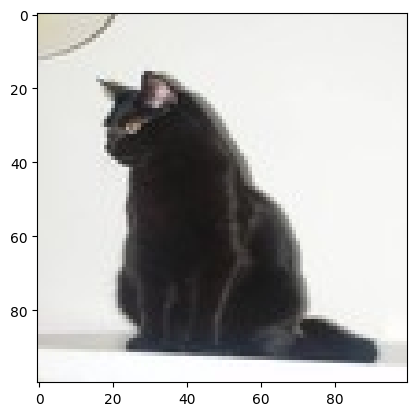

In [42]:
idx = random.randint(0,len(X_train))
plt.imshow(X_train[idx])
plt.show()

# train neural network

In [58]:
model = Sequential()
model.add(Flatten(input_shape=(100,100,3)))  #converts multidimensional data to 1D
model.add(Dense(128,activation='relu'))
model.add(Dense(128,activation='relu'))
model.add(Dense(1, activation='sigmoid'))


In [59]:
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_3 (Flatten)             │ (None, 30000)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 128)            │     3,840,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,856,769 (14.71 MB)

 Trainable params: 3,856,769 (14.71 MB)

 Non-trainable params: 0 (0.00 B)

In [60]:
model.compile(loss='categorical_crossentropy',optimizer='Adam',metrics=['accuracy'])  # categorical_crossentropy because my y labels are already onehot encoded 

In [61]:
history=model.fit(X_train,y_train,epochs=20,validation_split=0.2)

Epoch 1/20


f:\desktop\ML\.venv\Lib\site-packages\keras\src\losses\losses.py:34: SyntaxWarning: In loss categorical_crossentropy, expected y_pred.shape to be (batch_size, num_classes) with num_classes > 1. Received: y_pred.shape=(32, 1). Consider using 'binary_crossentropy' if you only have 2 classes.
  return self.fn(y_true, y_pred, **self._fn_kwargs)


50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step - accuracy: 0.6250 - loss: 0.0000e+00

f:\desktop\ML\.venv\Lib\site-packages\keras\src\losses\losses.py:34: SyntaxWarning: In loss categorical_crossentropy, expected y_pred.shape to be (batch_size, num_classes) with num_classes > 1. Received: y_pred.shape=(None, 1). Consider using 'binary_crossentropy' if you only have 2 classes.
  return self.fn(y_true, y_pred, **self._fn_kwargs)


50/50 ━━━━━━━━━━━━━━━━━━━━ 9s 85ms/step - accuracy: 0.6250 - loss: 0.0000e+00 - val_accuracy: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 2/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 3s 66ms/step - accuracy: 0.6250 - loss: 0.0000e+00 - val_accuracy: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 3/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 4s 73ms/step - accuracy: 0.6250 - loss: 0.0000e+00 - val_accuracy: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 4/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 3s 67ms/step - accuracy: 0.6250 - loss: 0.0000e+00 - val_accuracy: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 5/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 3s 68ms/step - accuracy: 0.6250 - loss: 0.0000e+00 - val_accuracy: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 6/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 5s 66ms/step - accuracy: 0.6250 - loss: 0.0000e+00 - val_accuracy: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 7/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 3s 66ms/step - accuracy: 0.6250 - loss: 0.0000e+00 - val_accuracy: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 8/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 